# 03. Transfer Learning LSTM

This notebook begins the transfer-learning stage of PondPredict.

The pretrained source-domain LSTM from `01_source_lstm.ipynb` will be reused and adapted to the Philippine pond dataset prepared in `02_philippine_baseline.ipynb`.

These initial cells only load and inspect the saved source model, recreate the exact Philippine split and sequences, and verify compatibility.

**No layer freezing or fine-tuning is performed yet.**

## 1. Import the Libraries

In [2]:
import os
os.environ["KERAS_BACKEND"] = "torch"

from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import joblib

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

import keras
from keras.models import load_model, Sequential
from keras.layers import LSTM, Dense, Dropout
from keras.callbacks import EarlyStopping
from keras.optimizers import Adam

## 2. Reproducibility Seed

In [3]:
RANDOM_SEED = 42
keras.utils.set_random_seed(RANDOM_SEED)
print("Random seed:", RANDOM_SEED)

Random seed: 42


## 3. Define Project Paths

This notebook uses the saved source model, the saved Philippine scaler, and the Philippine dataset.

In [4]:
SOURCE_MODEL_PATH = Path("../models/source_final.keras")
PH_SCALER_PATH = Path("../models/ph_scaler.pkl")
PH_DATA_PATH = Path("../data/PH_data.csv")

print("Source model exists:", SOURCE_MODEL_PATH.exists())
print("Philippine scaler exists:", PH_SCALER_PATH.exists())
print("Philippine data exists:", PH_DATA_PATH.exists())

if not SOURCE_MODEL_PATH.exists():
    raise FileNotFoundError("source_final.keras was not found.")

if not PH_SCALER_PATH.exists():
    raise FileNotFoundError("ph_scaler.pkl was not found.")

if not PH_DATA_PATH.exists():
    raise FileNotFoundError("PH_data.csv was not found.")

Source model exists: True
Philippine scaler exists: True
Philippine data exists: True


## 4. Load the Final Source Model

The final tuned source LSTM is loaded exactly as saved from the source-model notebook.

In [5]:
source_model = load_model(SOURCE_MODEL_PATH)

print("Source model loaded successfully.")
source_model.summary()

Source model loaded successfully.


Model: "sequential_16"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm_17 (LSTM)                  │ (None, 16)             │         1,216 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_14 (Dropout)            │ (None, 16)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_16 (Dense)                │ (None, 2)              │            34 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,752 (14.66 KB)

 Trainable params: 1,250 (4.88 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 2,502 (9.77 KB)

## 5. Inspect Source Model Layers

In [6]:
for i, layer in enumerate(source_model.layers):
    print(
        f"Layer {i}: "
        f"name={layer.name}, "
        f"type={layer.__class__.__name__}, "
        f"trainable={layer.trainable}, "
        f"params={layer.count_params()}"
    )

Layer 0: name=lstm_17, type=LSTM, trainable=True, params=1216
Layer 1: name=dropout_14, type=Dropout, trainable=True, params=0
Layer 2: name=dense_16, type=Dense, trainable=True, params=34


## 6. Inspect Source Model Weight Shapes

In [7]:
for i, layer in enumerate(source_model.layers):
    weights = layer.get_weights()

    print(f"\nLayer {i}: {layer.name} ({layer.__class__.__name__})")

    if len(weights) == 0:
        print("No weights in this layer.")
    else:
        for j, weight in enumerate(weights):
            print(f"Weight {j} shape: {weight.shape}")


Layer 0: lstm_17 (LSTM)
Weight 0 shape: (2, 64)
Weight 1 shape: (16, 64)
Weight 2 shape: (64,)

Layer 1: dropout_14 (Dropout)
No weights in this layer.

Layer 2: dense_16 (Dense)
Weight 0 shape: (16, 2)
Weight 1 shape: (2,)


## 7. Load and Prepare the Philippine Dataset

The Philippine dataset is reloaded using the same column names and timestamp handling used in the baseline notebook.

In [8]:
ph_df = pd.read_csv(PH_DATA_PATH)

ph_work = ph_df.rename(columns={
    "Date & Time": "created_date",
    "pH": "water_pH",
    "Water Temp (°C)": "water_temp"
}).copy()

ph_work["created_date"] = pd.to_datetime(
    ph_work["created_date"],
    format="%Y-%m-%d %H:%M"
)

ph_work = ph_work.sort_values("created_date").reset_index(drop=True)

ph_model = ph_work[
    ["created_date", "water_pH", "water_temp"]
].copy()

print("Rows:", len(ph_model))
print("Columns:", ph_model.columns.tolist())
print("First timestamp:", ph_model["created_date"].min())
print("Last timestamp:", ph_model["created_date"].max())
print("\nMissing values:")
print(ph_model.isnull().sum())

Rows: 288
Columns: ['created_date', 'water_pH', 'water_temp']
First timestamp: 2026-09-22 00:00:00
Last timestamp: 2026-10-03 23:00:00

Missing values:
created_date    0
water_pH        0
water_temp      0
dtype: int64


## 8. Recreate the Philippine Chronological Split

The exact same 70%-15%-15% chronological split used by the Philippine-only baseline is recreated.

In [9]:
ph_total_rows = len(ph_model)

ph_train_end = int(ph_total_rows * 0.70)
ph_val_end = int(ph_total_rows * 0.85)

ph_train_df = ph_model.iloc[:ph_train_end].copy()
ph_val_df = ph_model.iloc[ph_train_end:ph_val_end].copy()
ph_test_df = ph_model.iloc[ph_val_end:].copy()

print("Training rows:", len(ph_train_df))
print("Validation rows:", len(ph_val_df))
print("Test rows:", len(ph_test_df))

print("\nTRAINING")
print(ph_train_df["created_date"].min(), "to", ph_train_df["created_date"].max())

print("\nVALIDATION")
print(ph_val_df["created_date"].min(), "to", ph_val_df["created_date"].max())

print("\nTEST")
print(ph_test_df["created_date"].min(), "to", ph_test_df["created_date"].max())

Training rows: 201
Validation rows: 43
Test rows: 44

TRAINING
2026-09-22 00:00:00 to 2026-09-30 08:00:00

VALIDATION
2026-09-30 09:00:00 to 2026-10-02 03:00:00

TEST
2026-10-02 04:00:00 to 2026-10-03 23:00:00


## 9. Load the Philippine Scaler

The same Philippine scaler used by the baseline is loaded so that baseline and transfer learning use identical local normalization.

In [10]:
ph_scaler = joblib.load(PH_SCALER_PATH)

ph_train_scaled = ph_scaler.transform(
    ph_train_df[["water_pH", "water_temp"]]
)

ph_val_scaled = ph_scaler.transform(
    ph_val_df[["water_pH", "water_temp"]]
)

ph_test_scaled = ph_scaler.transform(
    ph_test_df[["water_pH", "water_temp"]]
)

print("Training scaled shape:", ph_train_scaled.shape)
print("Validation scaled shape:", ph_val_scaled.shape)
print("Test scaled shape:", ph_test_scaled.shape)

print("\nTraining min:", ph_train_scaled.min(axis=0))
print("Training max:", ph_train_scaled.max(axis=0))

Training scaled shape: (201, 2)
Validation scaled shape: (43, 2)
Test scaled shape: (44, 2)

Training min: [0. 0.]
Training max: [1. 1.]


## 10. Recreate the 6-Hour Philippine Sequences

The transfer-learning model uses the same forecasting task as the source model and Philippine-only baseline: six previous hourly observations to predict both variables one hour ahead.

In [11]:
PH_SEQUENCE_LENGTH = 6

def create_ph_sequences(scaled_values, sequence_length):
    X = []
    y = []

    for i in range(sequence_length, len(scaled_values)):
        X.append(scaled_values[i - sequence_length:i])
        y.append(scaled_values[i])

    return np.array(X), np.array(y)

X_ph_train, y_ph_train = create_ph_sequences(
    ph_train_scaled,
    PH_SEQUENCE_LENGTH
)

X_ph_val, y_ph_val = create_ph_sequences(
    ph_val_scaled,
    PH_SEQUENCE_LENGTH
)

X_ph_test, y_ph_test = create_ph_sequences(
    ph_test_scaled,
    PH_SEQUENCE_LENGTH
)

print("Training sequences:")
print("X_ph_train:", X_ph_train.shape)
print("y_ph_train:", y_ph_train.shape)

print("\nValidation sequences:")
print("X_ph_val:", X_ph_val.shape)
print("y_ph_val:", y_ph_val.shape)

print("\nTest sequences:")
print("X_ph_test:", X_ph_test.shape)
print("y_ph_test:", y_ph_test.shape)

Training sequences:
X_ph_train: (195, 6, 2)
y_ph_train: (195, 2)

Validation sequences:
X_ph_val: (37, 6, 2)
y_ph_val: (37, 2)

Test sequences:
X_ph_test: (38, 6, 2)
y_ph_test: (38, 2)


## 11. Final Compatibility Check

The source model and Philippine sequences must agree on input and output dimensionality before any learned weights are reused.

In [12]:
print("Source model input shape:", source_model.input_shape)
print("Source model output shape:", source_model.output_shape)

print("\nPhilippine training input shape:", X_ph_train.shape)
print("Philippine training target shape:", y_ph_train.shape)

print("\nExpected per-sequence input shape:", X_ph_train.shape[1:])
print("Expected target dimension:", y_ph_train.shape[1])

Source model input shape: (None, 6, 2)
Source model output shape: (None, 2)

Philippine training input shape: (195, 6, 2)
Philippine training target shape: (195, 2)

Expected per-sequence input shape: (6, 2)
Expected target dimension: 2


## 12. Identify Transferable Source Layers

In [13]:
source_lstm_layers = [
    layer for layer in source_model.layers
    if isinstance(layer, LSTM)
]

source_dropout_layers = [
    layer for layer in source_model.layers
    if isinstance(layer, Dropout)
]

source_dense_layers = [
    layer for layer in source_model.layers
    if isinstance(layer, Dense)
]

print("Number of LSTM layers:", len(source_lstm_layers))
print("Number of Dropout layers:", len(source_dropout_layers))
print("Number of Dense layers:", len(source_dense_layers))

if source_lstm_layers:
    print("\nSource LSTM layer name:", source_lstm_layers[0].name)
    print("Source LSTM units:", source_lstm_layers[0].units)

if source_dense_layers:
    print("Source Dense output units:", source_dense_layers[-1].units)

Number of LSTM layers: 1
Number of Dropout layers: 1
Number of Dense layers: 1

Source LSTM layer name: lstm_17
Source LSTM units: 16
Source Dense output units: 2


## 13. Transfer-Learning Strategy

The source and Philippine datasets use the same model input structure: six hourly observations with two variables, water pH and water temperature. Both models also forecast the same two variables one hour ahead.

The pretrained source LSTM therefore provides a compatible temporal feature representation for transfer learning.

The transfer-learning procedure is performed in two stages:

1. The learned weights of the source LSTM layer are transferred to a new Philippine target model. The transferred LSTM layer is initially frozen while a newly initialized output layer is trained using Philippine data.
2. The transferred LSTM layer is subsequently unfrozen and the complete target model is fine-tuned using a smaller learning rate.

A new Dense output layer is initialized for the Philippine target domain rather than directly transferring the source output-layer weights.

In [14]:
source_lstm_weights = source_lstm_layers[0].get_weights()

print("Number of transferred LSTM weight arrays:",
      len(source_lstm_weights))

for i, weight in enumerate(source_lstm_weights):
    print(
        f"Transferred weight {i} shape:",
        weight.shape
    )

Number of transferred LSTM weight arrays: 3
Transferred weight 0 shape: (2, 64)
Transferred weight 1 shape: (16, 64)
Transferred weight 2 shape: (64,)


## 15. Build the Transfer-Learning Target Model

A new target-domain model is created using the same core architecture as the source and Philippine-only baseline models.

The LSTM layer receives the learned source-domain LSTM weights, while the Dense output layer is newly initialized for the Philippine target domain.

In [15]:
keras.utils.set_random_seed(RANDOM_SEED)

transfer_model = Sequential([
    keras.Input(shape=(6, 2)),

    LSTM(
        16,
        name="transfer_lstm"
    ),

    Dropout(
        0.20,
        name="transfer_dropout"
    ),

    Dense(
        2,
        name="transfer_output"
    )
])

In [16]:
transfer_model.get_layer(
    "transfer_lstm"
).set_weights(
    source_lstm_weights
)

print("Source LSTM weights transferred successfully.")

Source LSTM weights transferred successfully.


In [17]:
transferred_weights = transfer_model.get_layer(
    "transfer_lstm"
).get_weights()

for i, (
    source_weight,
    transferred_weight
) in enumerate(
    zip(
        source_lstm_weights,
        transferred_weights
    )
):

    same = np.allclose(
        source_weight,
        transferred_weight
    )

    print(
        f"Weight array {i} identical:",
        same
    )

Weight array 0 identical: True
Weight array 1 identical: True
Weight array 2 identical: True


## 17. Stage 1: Freeze the Transferred LSTM

During the first transfer-learning stage, the pretrained LSTM layer is frozen.

This preserves the temporal patterns learned from the abundant source dataset while allowing the newly initialized Philippine output layer to adapt to the target domain.

In [18]:
transfer_model.get_layer(
    "transfer_lstm"
).trainable = False

In [19]:
for layer in transfer_model.layers:
    print(
        layer.name,
        "|",
        layer.__class__.__name__,
        "| trainable:",
        layer.trainable
    )

transfer_lstm | LSTM | trainable: False
transfer_dropout | Dropout | trainable: True
transfer_output | Dense | trainable: True


In [20]:
transfer_model.compile(
    optimizer=Adam(
        learning_rate=0.005
    ),
    loss="mse",
    metrics=["mae"]
)

transfer_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ transfer_lstm (LSTM)            │ (None, 16)             │         1,216 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ transfer_dropout (Dropout)      │ (None, 16)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ transfer_output (Dense)         │ (None, 2)              │            34 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,250 (4.88 KB)

 Trainable params: 34 (136.00 B)

 Non-trainable params: 1,216 (4.75 KB)

### 19. Stage 1 Early Stopping

In [21]:
stage1_early_stop = EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

## 20. Stage 1 Training

The transferred LSTM remains frozen while the newly initialized Philippine output layer is trained.

Validation loss is monitored using early stopping with a patience of five epochs.

In [22]:
stage1_history = transfer_model.fit(
    X_ph_train,
    y_ph_train,
    validation_data=(
        X_ph_val,
        y_ph_val
    ),
    epochs=100,
    batch_size=8,
    callbacks=[
        stage1_early_stop
    ],
    verbose=1
)

Epoch 1/100
 1/25 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - loss: 0.1181 - mae: 0.3352

25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0585 - mae: 0.2132 - val_loss: 0.0109 - val_mae: 0.0881
Epoch 2/100
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.0152 - mae: 0.0954 - val_loss: 0.0036 - val_mae: 0.0506
Epoch 3/100
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.0087 - mae: 0.0760 - val_loss: 0.0057 - val_mae: 0.0627
Epoch 4/100
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.0079 - mae: 0.0724 - val_loss: 0.0057 - val_mae: 0.0613
Epoch 5/100
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.0079 - mae: 0.0734 - val_loss: 0.0053 - val_mae: 0.0574
Epoch 6/100
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.0074 - mae: 0.0700 - val_loss: 0.0054 - val_mae: 0.0581
Epoch 7/100
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.0067 - mae: 0.0655 - val_loss: 0.0055 - val_mae: 0.0585


In [23]:
stage1_epochs_run = len(
    stage1_history.history["loss"]
)

stage1_best_epoch = (
    np.argmin(
        stage1_history.history["val_loss"]
    ) + 1
)

stage1_best_val_loss = min(
    stage1_history.history["val_loss"]
)

print("TRANSFER LEARNING - STAGE 1")
print(
    "Epochs actually run:",
    stage1_epochs_run
)
print(
    "Best epoch:",
    stage1_best_epoch
)
print(
    "Best validation loss:",
    stage1_best_val_loss
)

TRANSFER LEARNING - STAGE 1
Epochs actually run: 7
Best epoch: 2
Best validation loss: 0.0035953642800450325


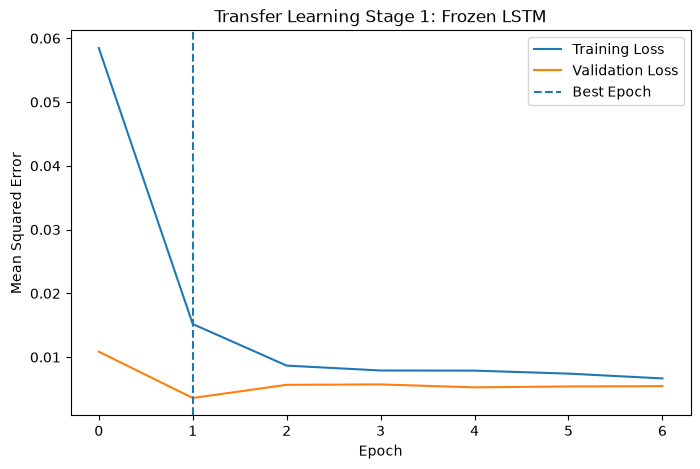

In [24]:
plt.figure(figsize=(8, 5))

plt.plot(
    stage1_history.history["loss"],
    label="Training Loss"
)

plt.plot(
    stage1_history.history["val_loss"],
    label="Validation Loss"
)

plt.axvline(
    stage1_best_epoch - 1,
    linestyle="--",
    label="Best Epoch"
)

plt.xlabel("Epoch")
plt.ylabel("Mean Squared Error")

plt.title(
    "Transfer Learning Stage 1: Frozen LSTM"
)

plt.legend()
plt.show()

## 23. Stage 2: Unfreeze and Fine-Tune the Transferred LSTM

After the newly initialized Philippine output layer has adapted to the target domain, the transferred LSTM layer is unfrozen.

The complete model is then fine-tuned using a smaller learning rate so that the transferred temporal representation can adapt gradually to the Philippine pond data without aggressively overwriting the source-domain knowledge.

In [25]:
transfer_model.get_layer(
    "transfer_lstm"
).trainable = True

In [26]:
for layer in transfer_model.layers:
    print(
        layer.name,
        "|",
        layer.__class__.__name__,
        "| trainable:",
        layer.trainable
    )

transfer_lstm | LSTM | trainable: True
transfer_dropout | Dropout | trainable: True
transfer_output | Dense | trainable: True


In [27]:
transfer_model.compile(
    optimizer=Adam(
        learning_rate=0.0005
    ),
    loss="mse",
    metrics=["mae"]
)

In [28]:
transfer_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ transfer_lstm (LSTM)            │ (None, 16)             │         1,216 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ transfer_dropout (Dropout)      │ (None, 16)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ transfer_output (Dense)         │ (None, 2)              │            34 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,250 (4.88 KB)

 Trainable params: 1,250 (4.88 KB)

 Non-trainable params: 0 (0.00 B)

In [29]:
stage2_early_stop = EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

In [30]:
stage2_history = transfer_model.fit(
    X_ph_train,
    y_ph_train,
    validation_data=(
        X_ph_val,
        y_ph_val
    ),
    epochs=100,
    batch_size=8,
    callbacks=[
        stage2_early_stop
    ],
    verbose=1
)

Epoch 1/100


25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0084 - mae: 0.0746 - val_loss: 0.0037 - val_mae: 0.0489
Epoch 2/100
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0068 - mae: 0.0651 - val_loss: 0.0041 - val_mae: 0.0488
Epoch 3/100
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.0079 - mae: 0.0702 - val_loss: 0.0049 - val_mae: 0.0552
Epoch 4/100
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.0065 - mae: 0.0620 - val_loss: 0.0044 - val_mae: 0.0501
Epoch 5/100
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0068 - mae: 0.0647 - val_loss: 0.0042 - val_mae: 0.0484
Epoch 6/100
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.0060 - mae: 0.0614 - val_loss: 0.0041 - val_mae: 0.0477


In [31]:
stage2_epochs_run = len(
    stage2_history.history["loss"]
)

stage2_best_epoch = (
    np.argmin(
        stage2_history.history["val_loss"]
    ) + 1
)

stage2_best_val_loss = min(
    stage2_history.history["val_loss"]
)

print("TRANSFER LEARNING - STAGE 2")

print(
    "Epochs actually run:",
    stage2_epochs_run
)

print(
    "Best epoch:",
    stage2_best_epoch
)

print(
    "Best validation loss:",
    stage2_best_val_loss
)

TRANSFER LEARNING - STAGE 2
Epochs actually run: 6
Best epoch: 1
Best validation loss: 0.0037248493172228336


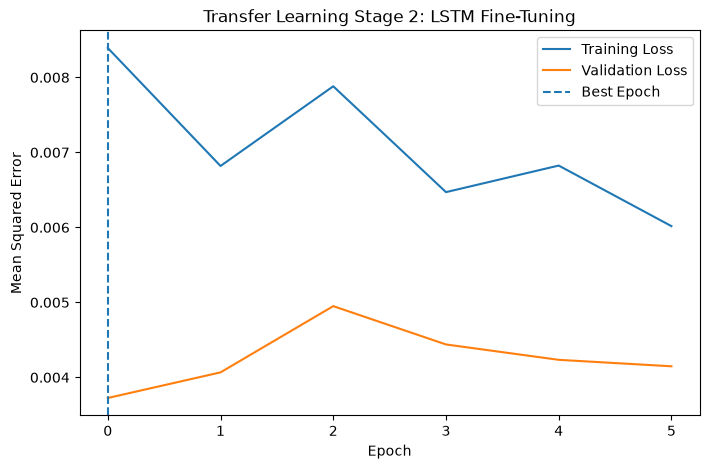

In [32]:
plt.figure(figsize=(8, 5))

plt.plot(
    stage2_history.history["loss"],
    label="Training Loss"
)

plt.plot(
    stage2_history.history["val_loss"],
    label="Validation Loss"
)

plt.axvline(
    stage2_best_epoch - 1,
    linestyle="--",
    label="Best Epoch"
)

plt.xlabel("Epoch")
plt.ylabel("Mean Squared Error")

plt.title(
    "Transfer Learning Stage 2: LSTM Fine-Tuning"
)

plt.legend()
plt.show()

## 29. Initial Transfer-Learning Result

The source LSTM weights were successfully transferred to the Philippine target model. All transferred LSTM weight arrays were verified to be identical to the corresponding source-model weights.

During Stage 1, the transferred LSTM layer was frozen and only the newly initialized Philippine output layer was trained. This configuration achieved a best validation loss of 0.003595 at epoch 2.

During the initial Stage 2 fine-tuning experiment, the transferred LSTM layer was unfrozen and trained using a learning rate of 0.0005. The best validation loss was 0.003725 at epoch 1.

Because the initial fine-tuning configuration did not improve upon the frozen-stage validation performance, smaller fine-tuning learning rates are evaluated before selecting the final transfer-learning configuration.

## 30. Reproducible Stage 1 Model

A clean transfer model is recreated using the same source LSTM weights and fixed random seed.

The frozen Stage 1 model is trained again and its best weights are preserved. Each fine-tuning learning-rate experiment will begin from these identical Stage 1 weights.

In [33]:
keras.utils.set_random_seed(RANDOM_SEED)

stage1_base_model = Sequential([
    keras.Input(shape=(6, 2)),

    LSTM(
        16,
        name="transfer_lstm"
    ),

    Dropout(
        0.20,
        name="transfer_dropout"
    ),

    Dense(
        2,
        name="transfer_output"
    )
])

stage1_base_model.get_layer(
    "transfer_lstm"
).set_weights(
    source_lstm_weights
)

stage1_base_model.get_layer(
    "transfer_lstm"
).trainable = False

stage1_base_model.compile(
    optimizer=Adam(
        learning_rate=0.005
    ),
    loss="mse",
    metrics=["mae"]
)

stage1_callback = EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

stage1_base_history = stage1_base_model.fit(
    X_ph_train,
    y_ph_train,
    validation_data=(
        X_ph_val,
        y_ph_val
    ),
    epochs=100,
    batch_size=8,
    callbacks=[stage1_callback],
    verbose=0
)

In [34]:
stage1_base_best_epoch = (
    np.argmin(
        stage1_base_history.history["val_loss"]
    ) + 1
)

stage1_base_best_loss = min(
    stage1_base_history.history["val_loss"]
)

print(
    "Stage 1 best epoch:",
    stage1_base_best_epoch
)

print(
    "Stage 1 best validation loss:",
    stage1_base_best_loss
)

Stage 1 best epoch: 2
Stage 1 best validation loss: 0.0035953642800450325


In [35]:
stage1_best_weights = (
    stage1_base_model.get_weights()
)

print(
    "Stage 1 weight arrays saved:",
    len(stage1_best_weights)
)

Stage 1 weight arrays saved: 5


In [36]:
def run_finetuning_experiment(
    learning_rate
):

    keras.utils.set_random_seed(
        RANDOM_SEED
    )

    model = Sequential([
        keras.Input(shape=(6, 2)),

        LSTM(
            16,
            name="transfer_lstm"
        ),

        Dropout(
            0.20,
            name="transfer_dropout"
        ),

        Dense(
            2,
            name="transfer_output"
        )
    ])

    # Start from the exact same
    # best Stage 1 weights.
    model.set_weights(
        stage1_best_weights
    )

    # Unfreeze the transferred LSTM.
    model.get_layer(
        "transfer_lstm"
    ).trainable = True

    model.compile(
        optimizer=Adam(
            learning_rate=learning_rate
        ),
        loss="mse",
        metrics=["mae"]
    )

    callback = EarlyStopping(
        monitor="val_loss",
        patience=5,
        restore_best_weights=True
    )

    history = model.fit(
        X_ph_train,
        y_ph_train,
        validation_data=(
            X_ph_val,
            y_ph_val
        ),
        epochs=100,
        batch_size=8,
        callbacks=[callback],
        verbose=0
    )

    best_epoch = (
        np.argmin(
            history.history["val_loss"]
        ) + 1
    )

    best_loss = min(
        history.history["val_loss"]
    )

    epochs_run = len(
        history.history["loss"]
    )

    return (
        model,
        history,
        best_epoch,
        best_loss,
        epochs_run
    )

In [37]:
(
    ft_0005_model,
    ft_0005_history,
    ft_0005_best_epoch,
    ft_0005_best_loss,
    ft_0005_epochs
) = run_finetuning_experiment(
    0.0005
)

print("Fine-tuning LR = 0.0005")
print("Best epoch:", ft_0005_best_epoch)
print("Epochs run:", ft_0005_epochs)
print(
    "Best validation loss:",
    ft_0005_best_loss
)

Fine-tuning LR = 0.0005
Best epoch: 14
Epochs run: 19
Best validation loss: 0.002990703796967864


In [38]:
(
    ft_0001_model,
    ft_0001_history,
    ft_0001_best_epoch,
    ft_0001_best_loss,
    ft_0001_epochs
) = run_finetuning_experiment(
    0.0001
)

print("Fine-tuning LR = 0.0001")
print("Best epoch:", ft_0001_best_epoch)
print("Epochs run:", ft_0001_epochs)
print(
    "Best validation loss:",
    ft_0001_best_loss
)

Fine-tuning LR = 0.0001
Best epoch: 6
Epochs run: 11
Best validation loss: 0.0035363142378628254


In [39]:
(
    ft_00005_model,
    ft_00005_history,
    ft_00005_best_epoch,
    ft_00005_best_loss,
    ft_00005_epochs
) = run_finetuning_experiment(
    0.00005
)

print("Fine-tuning LR = 0.00005")
print("Best epoch:", ft_00005_best_epoch)
print("Epochs run:", ft_00005_epochs)
print(
    "Best validation loss:",
    ft_00005_best_loss
)

Fine-tuning LR = 0.00005
Best epoch: 6
Epochs run: 11
Best validation loss: 0.0034787754993885756


## 36. Fine-Tuning Learning-Rate Comparison

The frozen Stage 1 configuration is compared with three fine-tuning learning rates.

All fine-tuning configurations begin from the exact same best Stage 1 weights so that the effect of the learning rate can be compared fairly.

In [40]:
finetuning_comparison = pd.DataFrame({
    "Configuration": [
        "Frozen Stage 1",
        "Fine-tune LR 0.0005",
        "Fine-tune LR 0.0001",
        "Fine-tune LR 0.00005"
    ],

    "Best Epoch": [
        stage1_base_best_epoch,
        ft_0005_best_epoch,
        ft_0001_best_epoch,
        ft_00005_best_epoch
    ],

    "Epochs Run": [
        len(
            stage1_base_history.history[
                "loss"
            ]
        ),
        ft_0005_epochs,
        ft_0001_epochs,
        ft_00005_epochs
    ],

    "Best Validation Loss": [
        stage1_base_best_loss,
        ft_0005_best_loss,
        ft_0001_best_loss,
        ft_00005_best_loss
    ]
})

finetuning_comparison

,Configuration,Best Epoch,Epochs Run,Best Validation Loss
0,Frozen Stage 1,2,7,0.003595
1,Fine-tune LR 0.0005,14,19,0.002991
2,Fine-tune LR 0.0001,6,11,0.003536
3,Fine-tune LR 0.00005,6,11,0.003479


In [41]:
best_transfer_row = (
    finetuning_comparison.loc[
        finetuning_comparison[
            "Best Validation Loss"
        ].idxmin()
    ]
)

print(
    "Best transfer configuration:",
    best_transfer_row["Configuration"]
)

print(
    "Best validation loss:",
    best_transfer_row[
        "Best Validation Loss"
    ]
)

Best transfer configuration: Fine-tune LR 0.0005
Best validation loss: 0.002990703796967864


## 37. Final Fine-Tuning Configuration

Three fine-tuning learning rates were evaluated after the frozen transfer-learning stage.

The validation results were:

- Frozen Stage 1: 0.003595
- Fine-tuning learning rate 0.0005: 0.002991
- Fine-tuning learning rate 0.0001: 0.003536
- Fine-tuning learning rate 0.00005: 0.003479

The learning rate of 0.0005 achieved the lowest validation loss.

Therefore, the final transfer-learning configuration uses one transferred LSTM layer that is initially frozen during Stage 1 and subsequently unfrozen during Stage 2 for fine-tuning with a learning rate of 0.0005.

In [42]:
final_transfer_model = ft_0005_model

print("Final transfer model selected:")
print("Fine-tuning learning rate: 0.0005")
print("Best fine-tuning epoch:", ft_0005_best_epoch)
print("Best validation loss:", ft_0005_best_loss)

Final transfer model selected:
Fine-tuning learning rate: 0.0005
Best fine-tuning epoch: 14
Best validation loss: 0.002990703796967864


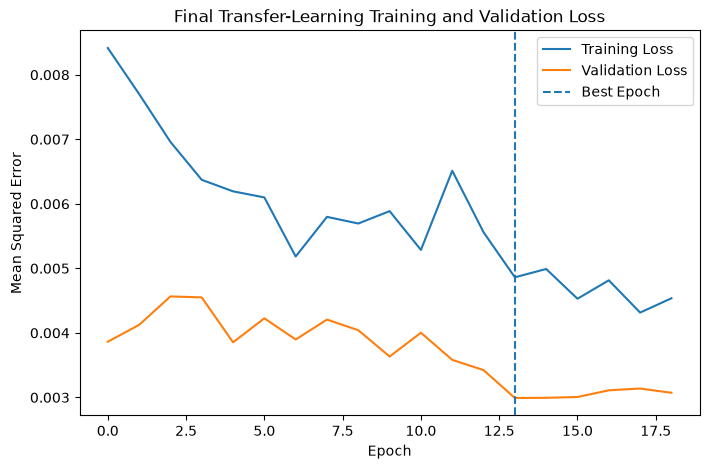

In [59]:
plt.figure(figsize=(8, 5))

plt.plot(
    ft_0005_history.history["loss"],
    label="Training Loss"
)

plt.plot(
    ft_0005_history.history["val_loss"],
    label="Validation Loss"
)

plt.axvline(
    ft_0005_best_epoch - 1,
    linestyle="--",
    label="Best Epoch"
)

plt.xlabel("Epoch")
plt.ylabel("Mean Squared Error")

plt.title(
    "Final Transfer-Learning Training and Validation Loss"
)

plt.legend()
plt.show()

In [60]:
transfer_val_pred_scaled = final_transfer_model.predict(
    X_ph_val,
    verbose=0
)

transfer_val_pred_original = ph_scaler.inverse_transform(
    transfer_val_pred_scaled
)

transfer_val_actual_original = ph_scaler.inverse_transform(
    y_ph_val
)

transfer_val_actual_ph = transfer_val_actual_original[:, 0]
transfer_val_pred_ph = transfer_val_pred_original[:, 0]

transfer_val_actual_temp = transfer_val_actual_original[:, 1]
transfer_val_pred_temp = transfer_val_pred_original[:, 1]

transfer_val_ph_mae = mean_absolute_error(
    transfer_val_actual_ph,
    transfer_val_pred_ph
)

transfer_val_ph_rmse = np.sqrt(
    mean_squared_error(
        transfer_val_actual_ph,
        transfer_val_pred_ph
    )
)

transfer_val_ph_r2 = r2_score(
    transfer_val_actual_ph,
    transfer_val_pred_ph
)

transfer_val_temp_mae = mean_absolute_error(
    transfer_val_actual_temp,
    transfer_val_pred_temp
)

transfer_val_temp_rmse = np.sqrt(
    mean_squared_error(
        transfer_val_actual_temp,
        transfer_val_pred_temp
    )
)

transfer_val_temp_r2 = r2_score(
    transfer_val_actual_temp,
    transfer_val_pred_temp
)

print("TRANSFER MODEL VALIDATION METRICS")
print()

print("pH")
print("MAE:", transfer_val_ph_mae)
print("RMSE:", transfer_val_ph_rmse)
print("R²:", transfer_val_ph_r2)

print()

print("Temperature")
print("MAE:", transfer_val_temp_mae)
print("RMSE:", transfer_val_temp_rmse)
print("R²:", transfer_val_temp_r2)

TRANSFER MODEL VALIDATION METRICS

pH
MAE: 0.026873374629665023
RMSE: 0.0322729713284426
R²: 0.8808852802128792

Temperature
MAE: 0.14790885512893284
RMSE: 0.19216718188950813
R²: 0.9854532963353683


In [43]:
final_transfer_model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ transfer_lstm (LSTM)            │ (None, 16)             │         1,216 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ transfer_dropout (Dropout)      │ (None, 16)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ transfer_output (Dense)         │ (None, 2)              │            34 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,752 (14.66 KB)

 Trainable params: 1,250 (4.88 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 2,502 (9.77 KB)

In [44]:
for layer in final_transfer_model.layers:
    print(
        layer.name,
        "|",
        layer.__class__.__name__,
        "| trainable:",
        layer.trainable
    )

transfer_lstm | LSTM | trainable: True
transfer_dropout | Dropout | trainable: True
transfer_output | Dense | trainable: True


## 40. Transfer-Learning Test Predictions

The selected transfer-learning model is evaluated on the held-out Philippine test sequences.

The same Philippine test partition used by the Philippine-only baseline is used here to ensure a direct and fair comparison.

In [45]:
transfer_pred_scaled = final_transfer_model.predict(
    X_ph_test,
    verbose=0
)

print(
    "Prediction shape:",
    transfer_pred_scaled.shape
)

print(
    "Actual target shape:",
    y_ph_test.shape
)

Prediction shape: (38, 2)
Actual target shape: (38, 2)


In [46]:
transfer_pred_original = ph_scaler.inverse_transform(
    transfer_pred_scaled
)

transfer_test_original = ph_scaler.inverse_transform(
    y_ph_test
)

In [47]:
transfer_actual_pH = transfer_test_original[:, 0]
transfer_actual_temp = transfer_test_original[:, 1]

transfer_pred_pH = transfer_pred_original[:, 0]
transfer_pred_temp = transfer_pred_original[:, 1]

print("First 5 actual values:")
print(transfer_test_original[:5])

print("\nFirst 5 transfer predictions:")
print(transfer_pred_original[:5])

First 5 actual values:
[[ 7.67 30.3 ]
 [ 7.69 30.9 ]
 [ 7.72 31.5 ]
 [ 7.74 32.1 ]
 [ 7.75 32.5 ]]

First 5 transfer predictions:
[[ 7.675646  30.036741 ]
 [ 7.7056913 30.708487 ]
 [ 7.7327275 31.34898  ]
 [ 7.758133  31.89902  ]
 [ 7.780798  32.406597 ]]


## 42. Transfer-Learning Evaluation Metrics

The final transfer-learning model is evaluated separately for water pH and water temperature using MAE, RMSE, and R².

The metrics are calculated after inverse transformation so that MAE and RMSE are reported in the original measurement scales.

In [50]:
# Water pH
transfer_pH_mae = mean_absolute_error(
    transfer_actual_pH,
    transfer_pred_pH
)

transfer_pH_rmse = np.sqrt(
    mean_squared_error(
        transfer_actual_pH,
        transfer_pred_pH
    )
)

transfer_pH_r2 = r2_score(
    transfer_actual_pH,
    transfer_pred_pH
)


# Water temperature
transfer_temp_mae = mean_absolute_error(
    transfer_actual_temp,
    transfer_pred_temp
)

transfer_temp_rmse = np.sqrt(
    mean_squared_error(
        transfer_actual_temp,
        transfer_pred_temp
    )
)

transfer_temp_r2 = r2_score(
    transfer_actual_temp,
    transfer_pred_temp
)


print("FINAL TRANSFER-LEARNING MODEL")

print("\nWATER pH")
print("MAE :", transfer_pH_mae)
print("RMSE:", transfer_pH_rmse)
print("R²  :", transfer_pH_r2)

print("\nWATER TEMPERATURE")
print("MAE :", transfer_temp_mae)
print("RMSE:", transfer_temp_rmse)
print("R²  :", transfer_temp_r2)

FINAL TRANSFER-LEARNING MODEL

WATER pH
MAE : 0.022977913304379028
RMSE: 0.028045673959904788
R²  : 0.8182993822589595

WATER TEMPERATURE
MAE : 0.15818147157367923
RMSE: 0.20453656015956012
R²  : 0.9855383242051322


In [51]:
transfer_metrics = pd.DataFrame({
    "Variable": [
        "Water pH",
        "Water Temperature"
    ],
    "MAE": [
        transfer_pH_mae,
        transfer_temp_mae
    ],
    "RMSE": [
        transfer_pH_rmse,
        transfer_temp_rmse
    ],
    "R2": [
        transfer_pH_r2,
        transfer_temp_r2
    ]
})

transfer_metrics

,Variable,MAE,RMSE,R2
0,Water pH,0.022978,0.028046,0.818299
1,Water Temperature,0.158181,0.204537,0.985538


## 44. Actual versus Predicted Philippine Water pH

The final transfer-learning model's one-hour-ahead pH predictions are compared with the actual Philippine test observations.

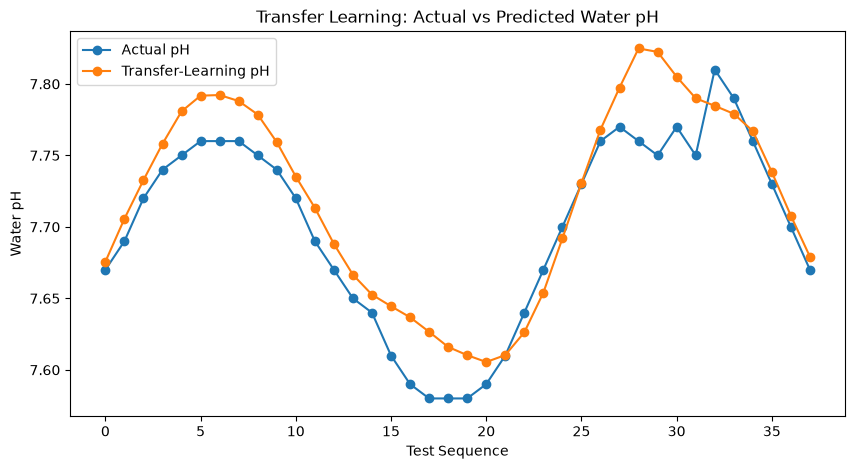

In [52]:
plt.figure(figsize=(10, 5))

plt.plot(
    transfer_actual_pH,
    marker="o",
    label="Actual pH"
)

plt.plot(
    transfer_pred_pH,
    marker="o",
    label="Transfer-Learning pH"
)

plt.xlabel("Test Sequence")
plt.ylabel("Water pH")

plt.title(
    "Transfer Learning: Actual vs Predicted Water pH"
)

plt.legend()
plt.show()

## 45. Actual versus Predicted Philippine Water Temperature

The final transfer-learning model's one-hour-ahead water-temperature predictions are compared with the actual Philippine test observations.

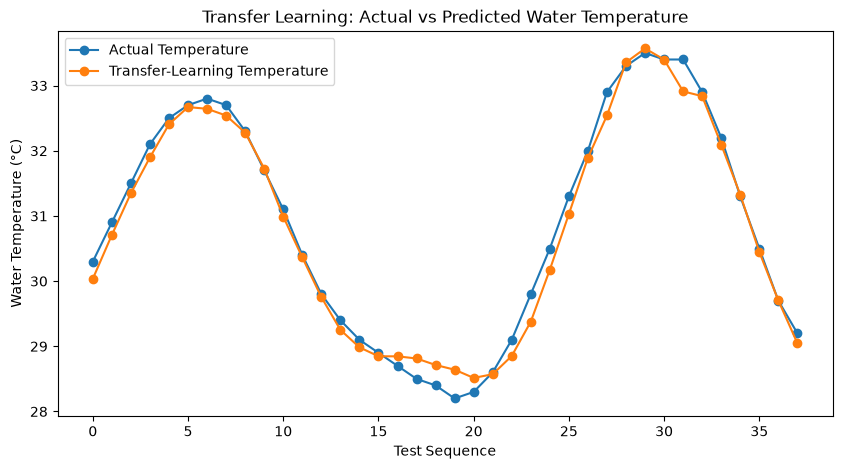

In [53]:
plt.figure(figsize=(10, 5))

plt.plot(
    transfer_actual_temp,
    marker="o",
    label="Actual Temperature"
)

plt.plot(
    transfer_pred_temp,
    marker="o",
    label="Transfer-Learning Temperature"
)

plt.xlabel("Test Sequence")
plt.ylabel("Water Temperature (°C)")

plt.title(
    "Transfer Learning: Actual vs Predicted Water Temperature"
)

plt.legend()
plt.show()

## 46. Save the Final Transfer-Learning Model

The selected transfer-learning model is saved for subsequent comparison with the Philippine-only baseline.

In [54]:
final_transfer_model.save(
    "../models/transfer_final.keras"
)

print("Final transfer-learning model saved.")

Final transfer-learning model saved.


In [55]:
transfer_metrics.to_csv(
    "../results/transfer_metrics.csv",
    index=False
)

print("Transfer metrics saved.")

Transfer metrics saved.


In [56]:
transfer_config = pd.DataFrame({
    "Parameter": [
        "Transferred Layer",
        "Transferred LSTM Units",
        "Stage 1 Frozen LSTM Layers",
        "Stage 1 Learning Rate",
        "Stage 2 Frozen LSTM Layers",
        "Fine-Tuning Learning Rate",
        "Batch Size",
        "Early Stopping Patience",
        "Early Stopping Monitor",
        "Sequence Length",
        "Forecast Horizon",
        "Random Seed"
    ],
    "Selected Value": [
        "LSTM",
        16,
        1,
        0.005,
        0,
        0.0005,
        8,
        5,
        "val_loss",
        "6 hours",
        "1 hour ahead",
        42
    ]
})

transfer_config

,Parameter,Selected Value
0,Transferred Layer,LSTM
1,Transferred LSTM Units,16
2,Stage 1 Frozen LSTM Layers,1
3,Stage 1 Learning Rate,0.005
4,Stage 2 Frozen LSTM Layers,0
5,Fine-Tuning Learning Rate,0.0005
6,Batch Size,8
7,Early Stopping Patience,5
8,Early Stopping Monitor,val_loss
9,Sequence Length,6 hours


In [57]:
transfer_config.to_csv(
    "../results/transfer_config.csv",
    index=False
)

finetuning_comparison.to_csv(
    "../results/frozen_layer_experiments.csv",
    index=False
)

print("Transfer configuration and experiments saved.")

Transfer configuration and experiments saved.


## 48. Final Transfer-Learning Result

The final transfer-learning LSTM was evaluated on the same 38 held-out Philippine test sequences used by the Philippine-only baseline.

The model achieved:

| Variable | MAE | RMSE | R² |
|---|---:|---:|---:|
| Water pH | 0.0230 | 0.0280 | 0.8183 |
| Water Temperature | 0.1582 | 0.2045 | 0.9855 |

Although the transfer-learning model successfully reused the source-domain LSTM weights and achieved high predictive performance, its test performance was lower than that of the Philippine-only baseline for both forecasting variables.

The Philippine-only baseline produced lower MAE and RMSE values and higher R² values for both water pH and water temperature.

Therefore, under the current full Philippine training-data configuration, transfer learning did not outperform training the same LSTM architecture directly on the Philippine dataset.

This result does not indicate that the transfer procedure failed. The source LSTM parameters were successfully transferred, frozen during initial target-domain adaptation, and subsequently fine-tuned. Rather, the result suggests that differences between the source and Philippine domains may limit the usefulness of the transferred representation when sufficient local training observations are available.

The effect of transfer learning under smaller quantities of Philippine training data will be examined separately in the local-data-quantity experiment.

In [58]:
quick_comparison = pd.DataFrame({
    "Model": [
        "PH-Only Baseline",
        "Transfer Learning",
        "PH-Only Baseline",
        "Transfer Learning"
    ],
    "Variable": [
        "Water pH",
        "Water pH",
        "Water Temperature",
        "Water Temperature"
    ],
    "MAE": [
        0.014402973275435523,
        transfer_pH_mae,
        0.11676285392359678,
        transfer_temp_mae
    ],
    "RMSE": [
        0.01885895112668206,
        transfer_pH_rmse,
        0.1603311556748475,
        transfer_temp_rmse
    ],
    "R2": [
        0.9178401359336488,
        transfer_pH_r2,
        0.9911138718608734,
        transfer_temp_r2
    ]
})

quick_comparison

,Model,Variable,MAE,RMSE,R2
0,PH-Only Baseline,Water pH,0.014403,0.018859,0.917840
1,Transfer Learning,Water pH,0.022978,0.028046,0.818299
2,PH-Only Baseline,Water Temperature,0.116763,0.160331,0.991114
3,Transfer Learning,Water Temperature,0.158181,0.204537,0.985538


## 50. Transfer-Learning Completion Summary

The transfer-learning implementation has been completed.

The final source-domain LSTM contained one 16-unit LSTM layer. Its learned recurrent weights were transferred to a structurally compatible Philippine target model.

During Stage 1, the transferred LSTM layer was frozen while a newly initialized target-domain output layer was trained. During Stage 2, the LSTM layer was unfrozen and fine-tuned using Philippine data.

Fine-tuning learning rates of 0.0005, 0.0001, and 0.00005 were evaluated. A learning rate of 0.0005 achieved the lowest validation loss and was selected for the final transfer-learning model.

The final transfer-learning model achieved:

- Water pH: MAE = 0.0230, RMSE = 0.0280, R² = 0.8183
- Water temperature: MAE = 0.1582, RMSE = 0.2045, R² = 0.9855

The transfer-learning model did not outperform the Philippine-only baseline when trained using the full available Philippine training partition. Further analysis will compare the models statistically and examine whether transfer learning provides greater benefit when smaller quantities of Philippine training data are available.